# Desenvolvimento do modelo de Multi Layer Perceptron (MLP) Classifier Binário de duas camadas ocultas
---

***A Fazeres:***
- Criar um limiar para o modelo dizer se é ou não ataque, com predict. EX.: se der 40% de chance de ser ataque, dizer que tem uma grande probabilidade de ser ataque

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay
from sklearn.feature_selection import RFE
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

### 2. Pacotes Predexan
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Buscando em: {caminho_predexan}")
print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Buscando em: C:\Users\rmaca\PUC_eixo7\projeto\pmv-si-2026-1-pe7-t3-g1-pesquisaexperimentacao-2026-1\src
Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 59 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   num_pacotes_origem                  96822 non-null  float64
 2   num_pacotes_destino                 96822 non-null  float64
 3   total_bytes_origem                  96822 non-null  float64
 4   total_bytes_destino                 96822 non-null  float64
 5   taxa_pacote                         96822 non-null  float64
 6   carga_origem                        96822 non-null  float64
 7   carga_destino                       96822 non-null  float64
 8   pacotes_perdidos_origem             96822 non-null  float64
 9   pacotes_perdidos_destino            96822 non-null  float64
 10  tempo_medio_pacote_origem           96822 non-null  float64
 11  bytes_por_pacote_destino            96822 non-null  floa

### 2. Determinando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   num_pacotes_origem                  49971 non-null  float64
 2   num_pacotes_destino                 49971 non-null  float64
 3   total_bytes_origem                  49971 non-null  float64
 4   total_bytes_destino                 49971 non-null  float64
 5   taxa_pacote                         49971 non-null  float64
 6   carga_origem                        49971 non-null  float64
 7   carga_destino                       49971 non-null  float64
 8   pacotes_perdidos_origem             49971 non-null  float64
 9   pacotes_perdidos_destino            49971 non-null  float64
 10  tempo_medio_pacote_origem           49971 non-null  float64
 11  bytes_por_pacote_destino            49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_treino é {type(X_treino)}. Possui {X_treino.shape[1]} features e {X_treino.shape[0]} registros.')
# Target
y_treino = df_treino['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_treino é {type(y_treino)}')

O tipo de X_treino é <class 'pandas.DataFrame'>. Possui 47 features e 96822 registros.
O tipo de y_treino é <class 'pandas.Series'>


### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')
# Target
y_teste = df_teste['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_teste é {type(y_teste)}')

O tipo de X_teste é <class 'pandas.DataFrame'>. Possui 45 features e 49971 registros.
O tipo de y_teste é <class 'pandas.Series'>


O dataset de teste possui duas features a menos: `servico_conexao_pop3` e `servico_conexao_ssh`. Desta forma, é necessário adicionar ambas, com os valores iguais a `0.0`:

In [7]:
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0.0)

print(f'Agora, o tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

Agora, o tipo de X_teste é <class 'pandas.DataFrame'>. Possui 47 features e 49971 registros.


### 3. Aplicação do Recursive Feature Elimination (RFE) para diminuição da dimensionalidade
---

O RFE usa o treino de um modelo para verificar as features mais importantes para o treino e teste. No caso, será usado XGBoost.

#### 3.1. Instanciamento da classe RFE
---

O intuito é que a dimensionalidade seja diminuida, e 10 features sejam escolhidas

In [43]:
xgb_estimador = XGBClassifier(random_state=42, eval_metric='logloss')

In [44]:
seletor_rfe = RFE(estimator=xgb_estimador, n_features_to_select=10)

#### 3.2. Aplicação do RFE em X_treino
---

In [45]:
seletor_rfe.fit_transform(X_treino, y_treino)

array([[-1.54433353e-01, -2.41770564e-03, -3.33333333e-01, ...,
         1.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 1.21303582e+01,  8.08271323e-01,  2.50000000e+00, ...,
         1.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 3.66647093e+00,  8.34429779e-02,  6.66666667e-01, ...,
         1.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       ...,
       [ 4.69348209e+00,  1.95689892e-01,  1.83333333e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 3.68761010e-01, -6.30313652e-04,  1.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [-1.00998238e-01, -8.29941346e-03, -1.66666667e-01, ...,
         1.00000000e+00,  0.00000000e+00,  0.00000000e+00]],
      shape=(96822, 10))

In [46]:
X_treino_reduzido = seletor_rfe.transform(X_treino)

In [47]:
colunas_originais = X_treino.columns
print(f'Registros e features de treino ANTES da aplicação do PCA:\n - Número de features e registros: {X_treino.shape}\n - Nomes das features: {X_treino.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do PCA:\n - Número de features e registros:  {X_treino_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do PCA:
 - Número de features e registros: (96822, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [48]:
X_treino_reduzido_df = pd.DataFrame(X_treino_reduzido, columns=colunas_selecionadas)
X_treino_reduzido_df.head()

,total_bytes_destino,carga_destino,pacotes_perdidos_destino,tempo_synack_ack,tamanho_medio_pacotes_origem,protocolo_rede_outros,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp-data,estado_conexao_CON
0,-0.154433,-0.002418,-0.333333,-0.004038,-0.547945,0.0,0.0,1.0,0.0,0.0
1,12.130358,0.808271,2.500000,-0.004038,-0.424658,0.0,0.0,1.0,0.0,0.0
2,3.666471,0.083443,0.666667,0.820533,-0.506849,0.0,0.0,1.0,0.0,0.0
3,0.021139,-0.010829,0.166667,-0.004038,-0.424658,0.0,0.0,0.0,0.0,0.0
4,-0.126248,-0.009800,-0.166667,0.931617,-0.410959,0.0,0.0,1.0,0.0,0.0


In [49]:
for feature in X_treino_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_treino_reduzido_df[feature].min()} a {X_treino_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_treino_reduzido_df[feature].max() - X_treino_reduzido_df[feature].min()}\n')


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4302.6576629477395

 - Magnitude: 4302.862595419848


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 36.700989512499405

 - Magnitude: 36.717318415859594


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 913.6666666666666

 - Magnitude: 914.0


Feature TEMPO_SYNACK_ACK:

 - Amplitude: de -0.00403792688985175 a 24.859196170876466

 - Magnitude: 24.863234097766316


Feature TAMANHO_MEDIO_PACOTES_ORIGEM:

 - Amplitude: de -0.7534246575342466 a 19.465753424657535

 - Magnitude: 20.21917808219178


Feature PROTOCOLO_REDE_OUTROS:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature PROTOCOLO_REDE_UDP:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature SERVICO_CONEXAO_-:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature SERVICO_CONEXAO_FTP-DATA:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature ESTADO_CONEXAO_CON:

 - Amplitude: de 0.0 a 1.0

 - Magnitude:

#### 3.3. Aplicação do RFE em X_teste
---

In [50]:
X_teste_reduzido = seletor_rfe.transform(X_teste)

In [51]:
colunas_originais = X_teste.columns
print(f'Registros e features de treino ANTES da aplicação do PCA:\n - Número de features e registros: {X_teste.shape}\n - Nomes das features: {X_teste.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do PCA:\n - Número de features e registros:  {X_teste_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do PCA:
 - Número de features e registros: (49971, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [52]:
X_teste_reduzido_df = pd.DataFrame(X_teste_reduzido, columns=colunas_selecionadas)
X_teste_reduzido_df.head()

,total_bytes_destino,carga_destino,pacotes_perdidos_destino,tempo_synack_ack,tamanho_medio_pacotes_origem,protocolo_rede_outros,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp-data,estado_conexao_CON
0,-0.204932,-0.016329,-0.333333,-0.004038,2.260274,0.0,1.0,1.0,0.0,0.0
1,-0.204932,-0.016329,-0.333333,-0.004038,10.931507,0.0,1.0,1.0,0.0,0.0
2,-0.204932,-0.016329,-0.333333,-0.004038,6.178082,0.0,1.0,1.0,0.0,0.0
3,-0.204932,-0.016329,-0.333333,-0.004038,5.027397,0.0,1.0,1.0,0.0,0.0
4,-0.204932,-0.016329,-0.333333,-0.004038,13.424658,0.0,1.0,1.0,0.0,0.0


In [53]:
for feature in X_teste_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_teste_reduzido_df[feature].min()} a {X_teste_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_teste_reduzido_df[feature].max() - X_teste_reduzido_df[feature].min()}\n')


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4303.239283617147

 - Magnitude: 4303.444216089255


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 34.078326484587734

 - Magnitude: 34.094655387947924


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 917.5

 - Magnitude: 917.8333333333334


Feature TEMPO_SYNACK_ACK:

 - Amplitude: de -0.00403792688985175 a 47.875280679371194

 - Magnitude: 47.879318606261045


Feature TAMANHO_MEDIO_PACOTES_ORIGEM:

 - Amplitude: de -0.8082191780821918 a 19.465753424657535

 - Magnitude: 20.273972602739725


Feature PROTOCOLO_REDE_OUTROS:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature PROTOCOLO_REDE_UDP:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature SERVICO_CONEXAO_-:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature SERVICO_CONEXAO_FTP-DATA:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature ESTADO_CONEXAO_CON:

 - Amplitude: de 0.0 a 1.0

 - Magnitude:

#### 3.4. Normalização das features pós RFE
---

In [54]:
escalonador_robusto = joblib.load('../../analise_exploratoria_pre_processamento/escalonadores/escalonador_robusto.pkl')

In [55]:
features_normalizar = ['total_bytes_destino', 'carga_destino', 'pacotes_perdidos_destino', 'tempo_synack_ack', 'tamanho_medio_pacotes_origem']

##### 3.4.1. Features de treino
---

In [56]:
# Transforma o bloco de colunas inteiro de uma vez para respeitar o formato esperado pelo Scikit-Learn e evitar erros de dimensionalidade no .transform()
df_treino_rfe_normalizado = pd.DataFrame(
    escalonador_robusto.fit_transform(X_treino_reduzido_df[features_normalizar]), 
    columns=features_normalizar, 
    index=X_treino_reduzido_df.index
)

# Iteração por todos os atributos, mostrando os valores antes e depois da Normalização e apenas transformando os dados que já foram aprendidos
for col in features_normalizar:

    _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_treino_reduzido_df, col)
    print(f'\n\n   -> Atributo {col.upper()}:\n')
    print(f'O atributo {col} possui amplitude entre {valor_min} e {valor_max} e magnitude {faixa} antes da Normalização com {escalonador_robusto}.\n')
    
    
    X_treino_reduzido_df.loc[:, col] = df_treino_rfe_normalizado[col]
    
    _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_treino_reduzido_df, col)
    print(f'O atributo {col} foi normalizado. Sua amplitude atual está entre {valor_min} e {valor_max}. Já sua magnitude é {faixa}.\n')

# Consolida as alterações no DataFrame e previne o aviso "PerformanceWarning: DataFrame is highly fragmented"
X_treino_reduzido_df = X_treino_reduzido_df.copy()



   -> Atributo TOTAL_BYTES_DESTINO:

O atributo total_bytes_destino possui amplitude entre -0.20493247210804463 e 4302.6576629477395 e magnitude 4302.862595419848 antes da Normalização com RobustScaler().

O atributo total_bytes_destino foi normalizado. Sua amplitude atual está entre -0.20493247210804463 e 4302.6576629477395. Já sua magnitude é 4302.862595419848.



   -> Atributo CARGA_DESTINO:

O atributo carga_destino possui amplitude entre -0.016328903360192524 e 36.700989512499405 e magnitude 36.717318415859594 antes da Normalização com RobustScaler().

O atributo carga_destino foi normalizado. Sua amplitude atual está entre -0.016328903360192524 e 36.700989512499405. Já sua magnitude é 36.717318415859594.



   -> Atributo PACOTES_PERDIDOS_DESTINO:

O atributo pacotes_perdidos_destino possui amplitude entre -0.3333333333333333 e 913.6666666666666 e magnitude 914.0 antes da Normalização com RobustScaler().

O atributo pacotes_perdidos_destino foi normalizado. Sua amplitude atual

##### 3.4.2. Features de teste
---

In [57]:
# Transforma o bloco de colunas inteiro de uma vez para respeitar o formato esperado pelo Scikit-Learn e evitar erros de dimensionalidade no .transform()
df_teste_rfe_normalizado = pd.DataFrame(
    escalonador_robusto.transform(X_teste_reduzido_df[features_normalizar]), 
    columns=features_normalizar, 
    index=X_teste_reduzido_df.index
)

# Iteração por todos os atributos, mostrando os valores antes e depois da Normalização e apenas transformando os dados que já foram aprendidos
for col in features_normalizar:

    _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_teste_reduzido_df, col)
    print(f'\n\n   -> Atributo {col.upper()}:\n')
    print(f'O atributo {col} possui amplitude entre {valor_min} e {valor_max} e magnitude {faixa} antes da Normalização com {escalonador_robusto}.\n')
    
    
    X_teste_reduzido_df.loc[:, col] = df_teste_rfe_normalizado[col]
    
    _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_teste_reduzido_df, col)
    print(f'O atributo {col} foi normalizado. Sua amplitude atual está entre {valor_min} e {valor_max}. Já sua magnitude é {faixa}.\n')

# Consolida as alterações no DataFrame e previne o aviso "PerformanceWarning: DataFrame is highly fragmented"
X_teste_reduzido_df = X_teste_reduzido_df.copy()



   -> Atributo TOTAL_BYTES_DESTINO:

O atributo total_bytes_destino possui amplitude entre -0.20493247210804463 e 4303.239283617147 e magnitude 4303.444216089255 antes da Normalização com RobustScaler().

O atributo total_bytes_destino foi normalizado. Sua amplitude atual está entre -0.20493247210804463 e 4303.239283617147. Já sua magnitude é 4303.444216089255.



   -> Atributo CARGA_DESTINO:

O atributo carga_destino possui amplitude entre -0.016328903360192524 e 34.078326484587734 e magnitude 34.094655387947924 antes da Normalização com RobustScaler().

O atributo carga_destino foi normalizado. Sua amplitude atual está entre -0.016328903360192524 e 34.078326484587734. Já sua magnitude é 34.094655387947924.



   -> Atributo PACOTES_PERDIDOS_DESTINO:

O atributo pacotes_perdidos_destino possui amplitude entre -0.3333333333333333 e 917.5 e magnitude 917.8333333333334 antes da Normalização com RobustScaler().

O atributo pacotes_perdidos_destino foi normalizado. Sua amplitude atual e

## D) Desenvolvimento do Modelo de MLP de Classificação com 47 features
---

### 1. Treino do modelo
---

#### 1.1. Instanciando a classe MLPClassifier
---

In [23]:
modelo = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, tol=0.0001, learning_rate_init=0.001, learning_rate='adaptive', validation_fraction=0.1, alpha=0.001, n_iter_no_change=15, solver="adam", activation='relu', verbose=True, random_state=42)

**Explicando os parâmetros utilizados em MLPClassifier:**

#### 1.2. Treino do modelo
---

Para o treino do modelo, é usada a expressão `modelo.fit(X_treino, y_treino)`. Será rodado em conjunto com a função `imprimir_tempo()` do módulo `metricas` do pacote `Predexan`, para poder ter o tempo de processamento registrado: 

In [24]:
pm.imprimir_desempenho(modelo.fit,X_treino, y_treino)

Iteration 1, loss = 0.44997528
Iteration 2, loss = 0.30599183
Iteration 3, loss = 0.28622169
Iteration 4, loss = 0.27384020
Iteration 5, loss = 0.23717760
Iteration 6, loss = 0.25990219
Iteration 7, loss = 0.23918176
Iteration 8, loss = 0.23708419
Iteration 9, loss = 0.22887412
Iteration 10, loss = 0.22733249
Iteration 11, loss = 0.21988071
Iteration 12, loss = 0.21157156
Iteration 13, loss = 0.21447552
Iteration 14, loss = 0.19987435
Iteration 15, loss = 0.21016168
Iteration 16, loss = 0.20051163
Iteration 17, loss = 0.19828844
Iteration 18, loss = 0.20562870
Iteration 19, loss = 0.19750287
Iteration 20, loss = 0.19696750
Iteration 21, loss = 0.19525903
Iteration 22, loss = 0.19223986
Iteration 23, loss = 0.19449545
Iteration 24, loss = 0.19110006
Iteration 25, loss = 0.18648950
Iteration 26, loss = 0.18638426
Iteration 27, loss = 0.18613793
Iteration 28, loss = 0.18544952
Iteration 29, loss = 0.18330852
Iteration 30, loss = 0.18388019
Iteration 31, loss = 0.18290569
Iteration 32, los

MLPClassifier(alpha=0.001, hidden_layer_sizes=(64, 32),
              learning_rate='adaptive', max_iter=2000, n_iter_no_change=15,
              random_state=42, verbose=True)

### 2. Realização de predições com os dados de teste
---

Para a predição probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo.predict_proba(X_teste)`. Para a predição binária, é expresso da mesma forma, mas com o uso do método `predict()`. Ambas terão seu desempenho medido pela função `imprimir_desempenho()` de `Predexan`.

#### 2.1. Predição Probababilística
---

In [25]:
y_predicao_probabilistica = pm.imprimir_desempenho(modelo.predict_proba, X_teste)[:,1]


--- RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO ---

Execução iniciada em: 24/05/2026 16:32:06

1. TEMPO: 0.2267s (0.00 min)

2. MEMÓRIA RAM (Processo Atual):
   - Pico de processamento: 54.52 MB
   - Diferença líquida de RAM no processo: 25.23 MB
   - Total RAM alocada para o processo: 437.42 MB

3. CPU:
   - Uso de CPU do sistema durante a execução: 51.9%

Execução concluída em: 24/05/2026 16:32:06



#### 2.2. Predição Binária
---

Para a Predição Binária, é usado o método `predict()` na seguinte expressão: `modelo.predict(X_teste)`

In [26]:
y_predicao_binaria = pm.imprimir_desempenho(modelo.predict, X_teste)


--- RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO ---

Execução iniciada em: 24/05/2026 16:32:06

1. TEMPO: 0.2245s (0.00 min)

2. MEMÓRIA RAM (Processo Atual):
   - Pico de processamento: 54.52 MB
   - Diferença líquida de RAM no processo: 0.00 MB
   - Total RAM alocada para o processo: 437.43 MB

3. CPU:
   - Uso de CPU do sistema durante a execução: 54.8%

Execução concluída em: 24/05/2026 16:32:06



In [27]:
type(y_predicao_binaria)

numpy.ndarray

### 3. Desempenho do modelo
---

O modelo possui métricas de desempenho baseadas nos resultados dos testes, sendo essas: 

- `Pontuação` que traz a `Acurácia Geral`.
- `Matriz de Confusão`:  permite a visualização do desempenho do modelo, uma vez que mostra o total de predições Verdadeiras Positivas (TP), Verdadeiras Negativa (TN), Falsas Positivas (FP) e Falsas Negativas (FN). No contexto do projeto, que visa a probailidade de detecção de ameaças, os alvos são sempre atingir ao máximoTN e TP, mas FN é o erro crítico, pois pode levar ao usuário da aplicação a ignorar a hipótese do ataque em sua máquina, podendo propiciar uma piora no caso, já que este pode deixar de buscar ajuda e manutenções e FP é o alarme falso.
- `Relatório de Classificação` que traz cálculos como `Precision`, `Recall` e `F1-Score`.
- `Curva ROC AUC` que traz uma visualização gráfica.
- `Curva Precision-Recall`

Serão feitos testes com limiares para se determinar qual deles tem melhor desempenho, revocação e precisão. As seguintes sub-seções trarão as métricas e gráficos de forma individual para cada teste.

#### 3.1. Limiar Não Customizado
---

##### 3.1.1. Matriz de Confusão
---

<Axes: >

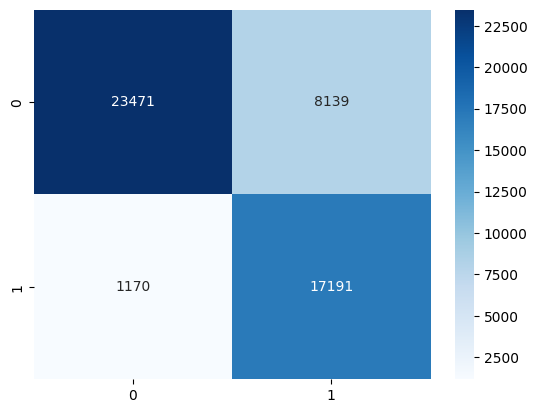

In [28]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_binaria)
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues')

In [29]:
(tn, fp), (fn, tp) = matriz_confusao
total = (tn+fn+tp+fp)

In [30]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 23471 casos que o modelo apontou como resultado negativo, corretamente. Representa 46.97% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 1170 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 2.34% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 17191 casos em que o modelo apontou como resultado positivo, corretamente. Representa 34.40% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 8139 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 16.29% do total de predições 

##### 3.1.2. Relatório de Classificação
---

In [31]:
relatorio_classificacao = classification_report(y_teste, y_predicao_binaria)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.95      0.74      0.83     31610
         1.0       0.68      0.94      0.79     18361

    accuracy                           0.81     49971
   macro avg       0.82      0.84      0.81     49971
weighted avg       0.85      0.81      0.82     49971



##### 3.1.3. Curva ROC-AUC
---

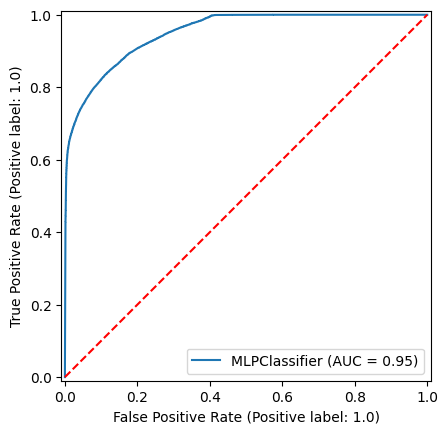

In [32]:
pg.gerar_roc_auc(modelo, X_teste,y_teste)

##### 3.1.4. Curva Precision-Recall
---

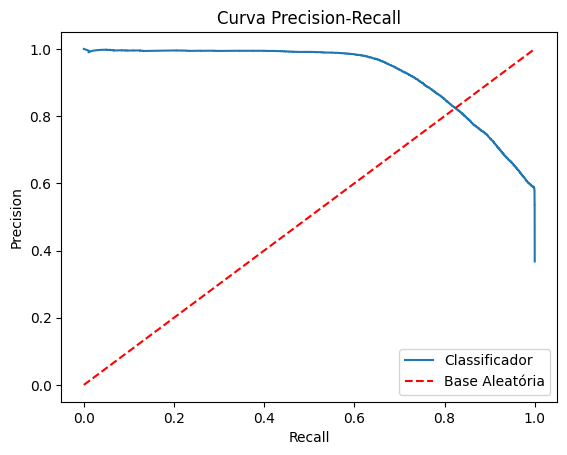

In [33]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica)

In [34]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True, obj_f2=True)


--- Objetivo focado em Recall (meta = 95.0%) ---
Limiar ideal a ser usado: 0.4606
Recall real obtido: 95.00% (Ataques detectados)
Precision real obtida: 66.01% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
Limiar ideal a ser usado: 0.9325
Recall real obtido: 68.31% (Ataques detectados)
Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
Limiar ideal: 0.7854
Recall neste ponto: 79.91% (Ataques detectados)
Precision neste ponto: 85.19% (Acerto dos alertas)

 - Equilíbrio Otimizado para Recall (Max F2-Score)
Limiar ideal: 0.0507
Recall neste ponto: 99.77% (Ataques detectados)
Precision neste ponto: 58.91% (Acerto dos alertas)


#### 3.2. Limiar Customizado
---

In [35]:
y_predicao_probabilistica_customizada = (y_predicao_probabilistica > 0.35).astype(int)

<Axes: >

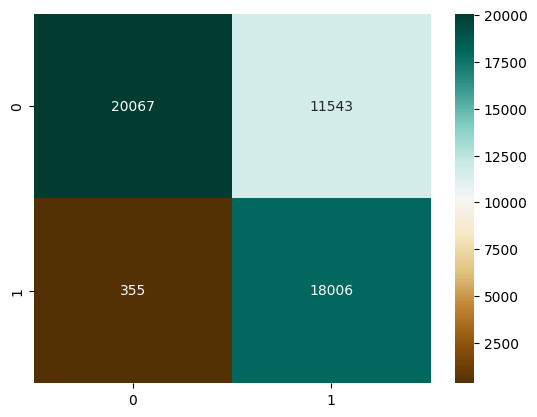

In [36]:
matriz_confusao_customizada = confusion_matrix(y_teste, y_predicao_probabilistica_customizada)
sns.heatmap(matriz_confusao_customizada, annot=True, fmt='d', cmap='BrBG')

In [37]:
(tn, fp), (fn, tp) = matriz_confusao_customizada
total = (tn+fn+tp+fp)

In [38]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 20067 casos que o modelo apontou como resultado negativo, corretamente. Representa 40.16% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 355 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 0.71% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 18006 casos em que o modelo apontou como resultado positivo, corretamente. Representa 36.03% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 11543 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 23.10% do total de predições 

In [39]:
relatorio_classificacao = classification_report(y_teste, y_predicao_probabilistica_customizada)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.98      0.63      0.77     31610
         1.0       0.61      0.98      0.75     18361

    accuracy                           0.76     49971
   macro avg       0.80      0.81      0.76     49971
weighted avg       0.85      0.76      0.76     49971



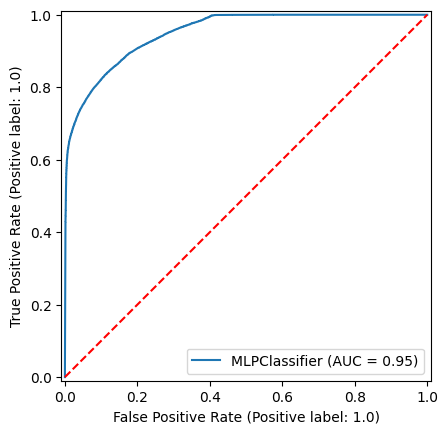

In [40]:
curva = RocCurveDisplay.from_estimator(modelo, X_teste, y_teste)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.show()

<div style="text-align: center;">
  <img src="../../imagens/formula_precisao.png" width="400">
</div>

2. Recall (Revocação): tem como foco evitar omissões do modelo. Um recall alto significa que o modelo consegue percorrer por quase todos os casos importantes, mesmo que arrisque alguns alarmes falsos, mas evite falsos negativos.

<div style="text-align: center;">
  <img src="../../imagens/formula_recall.png" width="400">
</div>

3. F1-Score (Valor F1): É a média harmônica entre Precision e Recall. Boa métrica para perceber quando se tem classes desbalanceadas e precisa de um único número que resuma a eficiência da predição.

<div style="text-align: center;">
  <img src="../../imagens/formula_f1score.png" width="400">
</div>

A curva `ROC (Receiver Operating Characteristic)` e a métrica `AUC (Area Under the Curve)` são ferramentas muito importantes para a medição de desempenho de `Modelos de Classificação`. Ela mede a capacidade do modelo em distinguir as classes: quanto maior o AUC, melhor o modelo é em prever 0 como 0 e 1 como 1, mas ainda assim, é melhor para medir o desempenho das probabilidades com o método `predict_proba` do que com o `predict`.

1. Curva ROC: É um gráfico que ilustra o equilíbrio entre a Taxa de Verdadeiros Positivos (Sensibilidade) e a Taxa de Falsos Positivos (1 - Especificidade) para todos os limiares (thresholds) possíveis de classificação.

2. AUC (Área sob a Curva): É um valor numérico que varia de 0 a 1 e resume a performance do modelo:

   - 1.0: Classificador perfeito.

   - 0.5: Classificador aleatório (equivalente ao acaso).

   -  Acima de 0.7: Geralmente indica um bom poder preditivo.
  
3. Os eixos são os seguintes:

    - Eixo Y (Taxa de Verdadeiro Positivo / Sensibilidade): Representa o Recall. Quanto mais alto, melhor para o modelo, já que este será mais abrangente ao processar os dados, conseguindo capturar um maior número de ameaças.

    - Eixo X (Taxa de Falso Positivo): É o custo do erro. Ele mostra, em relação a todos os casos normais, quantos o modelo marcou erradamente como ameaça. Quanto mais baixo (à esquerda), melhor.
  
4. A "Linha de Sorte" (Pontilhada):

    - A linha diagonal representa um modelo que decide com aleatoriedade.

    - Se curva estiver próximo a essa linha diagonal, ele será pouco útil.
  
    - Se estiver acima, mais distante, terá uma utilidade maior, por não depender tanto de aleatoriedade.
  
5. O Ponto Ideal:

    O objetivo do modelo é chegar o mais próximo possível do canto superior esquerdo (coordenada 0.0 no X e 1.0 no Y). 

## E) Desenvolvimento do Modelo de MLP de Classificação com 10 features (RFE + XGBoost Classifier)
---

### 1. Treino do modelo
---

#### 1.1. Instanciando a classe MLPClassifier
---

In [58]:
modelo_rfe = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, tol=0.0001, learning_rate_init=0.001, learning_rate='adaptive', validation_fraction=0.1, alpha=0.001, n_iter_no_change=15, solver="adam", activation='relu', verbose=True, random_state=42)

#### 1.2. Treino do modelo
---

Para o treino do modelo, é usada a expressão `modelo.fit(X_treino, y_treino)`. Será rodado em conjunto com a função `imprimir_tempo()` do módulo `metricas` do pacote `Predexan`, para poder ter o tempo de processamento registrado: 

In [59]:
pm.imprimir_desempenho(modelo_rfe.fit,X_treino_reduzido_df, y_treino)

Iteration 1, loss = 0.39769740
Iteration 2, loss = 0.26976668
Iteration 3, loss = 0.25271743
Iteration 4, loss = 0.24270674
Iteration 5, loss = 0.23845231
Iteration 6, loss = 0.24152768
Iteration 7, loss = 0.22996467
Iteration 8, loss = 0.22693570
Iteration 9, loss = 0.22656309
Iteration 10, loss = 0.23725208
Iteration 11, loss = 0.23103363
Iteration 12, loss = 0.22089796
Iteration 13, loss = 0.21623782
Iteration 14, loss = 0.21851355
Iteration 15, loss = 0.22228615
Iteration 16, loss = 0.21482125
Iteration 17, loss = 0.20992588
Iteration 18, loss = 0.21778182
Iteration 19, loss = 0.20976359
Iteration 20, loss = 0.20669897
Iteration 21, loss = 0.20653725
Iteration 22, loss = 0.20850337
Iteration 23, loss = 0.20524861
Iteration 24, loss = 0.20634499
Iteration 25, loss = 0.20493847
Iteration 26, loss = 0.20505378
Iteration 27, loss = 0.20565559
Iteration 28, loss = 0.20281234
Iteration 29, loss = 0.20488904
Iteration 30, loss = 0.20222539
Iteration 31, loss = 0.20363485
Iteration 32, los

MLPClassifier(alpha=0.001, hidden_layer_sizes=(64, 32),
              learning_rate='adaptive', max_iter=2000, n_iter_no_change=15,
              random_state=42, verbose=True)

### 2. Realização de predições com os dados de teste
---

Para a predição probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo.predict_proba(X_teste)`. Para a predição binária, é expresso da mesma forma, mas com o uso do método `predict()`. Ambas terão seu desempenho medido pela função `imprimir_desempenho()` de `Predexan`.

#### 2.1. Predição Probababilística
---

In [65]:
y_predicao_probabilistica_rfe = pm.imprimir_desempenho(modelo_rfe.predict_proba, X_teste_reduzido_df)[:,1]


--- RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO ---

Execução iniciada em: 24/05/2026 16:56:30

1. TEMPO: 0.2342s (0.00 min)

2. MEMÓRIA RAM (Processo Atual):
   - Pico de processamento: 36.60 MB
   - Diferença líquida de RAM no processo: 0.00 MB
   - Total RAM alocada para o processo: 379.87 MB

3. CPU:
   - Uso de CPU do sistema durante a execução: 77.0%

Execução concluída em: 24/05/2026 16:56:30



#### 2.2. Predição Binária
---

In [66]:
y_predicao_binaria_rfe = pm.imprimir_desempenho(modelo_rfe.predict, X_teste_reduzido_df)


--- RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO ---

Execução iniciada em: 24/05/2026 16:56:30

1. TEMPO: 0.2080s (0.00 min)

2. MEMÓRIA RAM (Processo Atual):
   - Pico de processamento: 36.60 MB
   - Diferença líquida de RAM no processo: 0.05 MB
   - Total RAM alocada para o processo: 379.91 MB

3. CPU:
   - Uso de CPU do sistema durante a execução: 75.6%

Execução concluída em: 24/05/2026 16:56:30



### 3. Desempenho do modelo
---

#### 3.1. Limiar Não Customizado
---

##### 3.1.1. Matriz de Confusão
---

<Axes: >

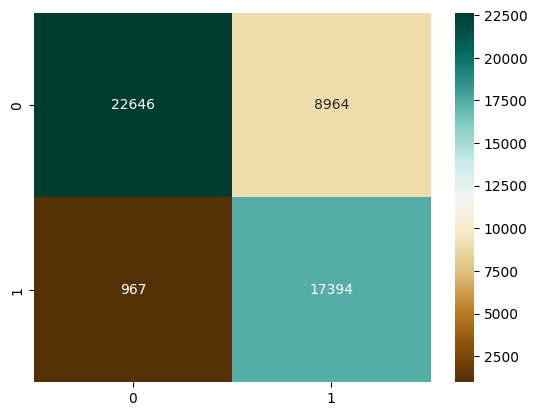

In [67]:
matriz_confusao_rfe = confusion_matrix(y_teste, y_predicao_binaria_rfe)
sns.heatmap(matriz_confusao_rfe, annot=True, fmt='d', cmap='BrBG')

In [68]:
(tn, fp), (fn, tp) = matriz_confusao_rfe
total = (tn+fn+tp+fp)

In [69]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 22646 casos que o modelo apontou como resultado negativo, corretamente. Representa 45.32% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 967 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 1.94% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 17394 casos em que o modelo apontou como resultado positivo, corretamente. Representa 34.81% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 8964 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 17.94% do total de predições d

##### 3.1.2. Relatório de Classificação
---

In [70]:
relatorio_classificacao = classification_report(y_teste, y_predicao_binaria_rfe)
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.96      0.72      0.82     31610
         1.0       0.66      0.95      0.78     18361

    accuracy                           0.80     49971
   macro avg       0.81      0.83      0.80     49971
weighted avg       0.85      0.80      0.80     49971



##### 3.1.3. Curva ROC-AUC
---

In [71]:
pg.gerar_roc_auc(modelo, X_teste_reduzido_df,y_teste)

Erro de valor. Confira a tipagem e o formato dos dados enviados. Detalhes: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- bytes_por_pacote_destino
- carga_origem
- conexoes_recentes_ip_porta_destino
- conexoes_recentes_ip_porta_origem
- duracao_conexao_seg
- ...



##### 3.1.4. Curva Precision-Recall
---

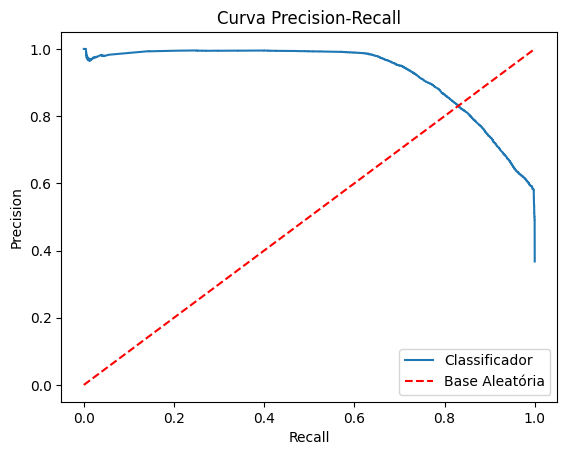

In [72]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_rfe)

In [73]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_rfe, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True, obj_f2=True)


--- Objetivo focado em Recall (meta = 95.0%) ---
Limiar ideal a ser usado: 0.4933
Recall real obtido: 95.00% (Ataques detectados)
Precision real obtida: 65.40% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
Limiar ideal a ser usado: 0.8971
Recall real obtido: 70.43% (Ataques detectados)
Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
Limiar ideal: 0.7579
Recall neste ponto: 80.94% (Ataques detectados)
Precision neste ponto: 85.46% (Acerto dos alertas)

 - Equilíbrio Otimizado para Recall (Max F2-Score)
Limiar ideal: 0.4106
Recall neste ponto: 98.01% (Ataques detectados)
Precision neste ponto: 61.19% (Acerto dos alertas)


### 4. Persisitindo o Modelo -> Ver o Pipeline do SKLEARN
---

In [ ]:
# joblib.dump(modelo, '../modelos_persistentes/mlp/binario/mlp_binario_2c.pkl')

In [76]:
joblib.dump(modelo_rfe, '../modelos_persistentes/mlp/binario/mlp_binario_rfe_2c.pkl')

['../modelos_persistentes/mlp/binario/mlp_binario_rfe_2c.pkl']